### BCSE432E Reinforcement Learning Lab: L29+L30
### Lab Assignment 11

### Simple vs Advanced Actor-Critic Reinforcement Learning for Fuel-Efficient Autonomous Delivery

### Name: Yashvanth Karunakaran (23BAI1589)

### AIM:
To Implement a python program to design an actor-critic reinforcement
learning agent to optimize the fuel efficiency of an autonomous
delivery vehicle by deciding when to accelerate, brake, or maintain
speed, given varying traffic conditions and road layouts.

Github Link: [https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-11.ipynb](https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-11.ipynb)

## Delivery Agent 

state = [speed, traffic, road, distance, clearance]

Action 0: Brake, Action 1: Maintain speed, Action 2: Accelerate

### Environment formulas

Fuel consumption is calculated as:

fuel = basic fuel + speed fuel + speed squared fuel + acceleration fuel

Safe speed is calculated as:

safe speed = speed limit * (1 - 0.55 * traffic - 0.25 * road)

Unsafe speed is calculated as:

unsafe = maximum of 0 and (current speed - safe speed)

Progress is calculated as:

progress = current speed / speed limit

The reward encourages progress, low fuel consumption, and safe driving:

reward = 2 * progress - 3 * fuel - 0.08 * unsafe

In [1]:
import numpy as np

SEED = 42

class DeliveryEnv:
    """
    Delivery Environment
    Actions: 0 - Brake, 1 - Maintain, 2 - Accelerate
    States: Speed, Traffic, Road, Distance, Clearance
    Reward: 2 * Progress - 3 * Fuel - 0.08 * Unsafe
    SafeSpeed: Speed limit * (1 - 0.55 * Traffic - 0.25 * Road)
    Unsafe: max(0, Speed - SafeSpeed)
    """

    def __init__(self, max_steps=100, seed=None):
        self.max_steps = max_steps
        self.speed_limit = 60.0
        self.rng = np.random.default_rng(seed)

    def reset(self, seed = SEED):
        self.speed = 20.0
        self.distance = 1.0
        self.steps = 0
        self.traffic = self.rng.random()
        self.road = self.rng.random()
        self.clearance = 1.0 - self.traffic
        return self.state()

    def state(self):
        return np.array([
            self.speed / 80.0,
            self.traffic,
            self.road,
            self.distance,
            self.clearance
        ], dtype=np.float32)

    def step(self, action):
        old_speed = self.speed

        if action == 0:    
            self.speed -= 6.0
        elif action == 2:
            self.speed += 6.0

        self.speed = np.clip(self.speed, 0.0, 80.0)
        self.traffic = self.rng.random()
        self.road = self.rng.random()
        self.clearance = np.clip(1.0 - 0.65 * self.traffic - 0.25 * self.road, 0.0, 1.0)

        acceleration = self.speed - old_speed
        fuel = 0.02 + 0.0008 * self.speed + 0.00004 * self.speed ** 2 + 0.003 * max(acceleration, 0.0) + 0.001 * abs(acceleration)

        safe_speed = self.speed_limit * (1.0 - 0.55 * self.traffic - 0.25 * self.road)
        unsafe = max(0.0, self.speed - safe_speed)
        progress = self.speed / self.speed_limit
        reward = 2.0 * progress - 3.0 * fuel - 0.08 * unsafe

        self.distance -= self.speed / (self.speed_limit * self.max_steps)
        self.steps += 1
        done = self.distance <= 0.0 or self.steps >= self.max_steps

        return self.state(), float(reward), done, float(fuel)

### Actor Critic Network

In [2]:
import torch
import torch.nn as nn

class ActorCritic(nn.Module):
    def __init__(self, state_dim=5, action_dim=3):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU()
        )
        self.actor = nn.Linear(64, action_dim)
        self.critic = nn.Linear(64, 1)

    def forward(self, state):
        features = self.shared(state)
        policy = torch.softmax(self.actor(features), dim=-1)
        value = self.critic(features)
        return policy, value

### Simple Actor-Critic: Monte Carlo method

1. Collect all rewards during the episode.

2. Calculate the discounted return from the end of the episode:
   return = reward + GAMMA * next_return

3. Calculate the advantage:
   advantage = complete_return - current_state_value

4. Actor loss:
   actor_loss = -log_probability(action) * advantage

5. Critic loss:
   critic_loss = squared_error(current_state_value, complete_return)

6. Total loss:
   total_loss = actor_loss + 0.5 * critic_loss

In [ ]:
import torch.optim as optim
from torch.distributions import Categorical

GAMMA = 0.99
LEARNING_RATE = 0.001
EPISODES = 200

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

simple_model = ActorCritic().to(device)
simple_optimizer = optim.Adam(
    simple_model.parameters(),
    lr=LEARNING_RATE
)

simple_history_reward = []
simple_history_fuel = []

for episode in range(EPISODES):
    env = DeliveryEnv(seed=SEED + episode)
    state = env.reset()
    done = False

    log_probs = []
    values = []
    rewards = []
    total_reward = 0.0
    total_fuel = 0.0

    while not done:
        state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)
        policy, value = simple_model(state_tensor)
        dist = Categorical(policy)
        action = dist.sample()

        next_state, reward, done, fuel = env.step(action.item())

        log_probs.append(dist.log_prob(action))
        values.append(value.squeeze())
        rewards.append(reward)
        total_reward += reward
        total_fuel += fuel
        state = next_state

    returns = []
    discounted_return = 0.0

    for reward in reversed(rewards):
        discounted_return = reward + GAMMA * discounted_return
        returns.insert(0, discounted_return)

    returns = torch.tensor(returns, dtype=torch.float32, device=device)
    values = torch.stack(values)
    log_probs = torch.stack(log_probs)

    advantages = returns - values
    actor_loss = -log_probs * advantages.detach().mean()
    critic_loss = nn.functional.mse_loss(values, returns)
    loss = actor_loss + 0.5 * critic_loss

    simple_optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(simple_model.parameters(), 1.0)
    simple_optimizer.step()

    simple_history_reward.append(total_reward)
    simple_history_fuel.append(total_fuel)

    if (episode + 1) % 10 == 0 or episode == 0:
        print(f"Episode {episode + 1}: Mean Reward = {np.mean(simple_history_reward[-50:])}, Mean Fuel = {np.mean(simple_history_fuel[-50:])}")

Episode 1: Mean Reward = -65.18, Mean Fuel = 22.9749
Episode 10: Mean Reward = 11.31, Mean Fuel = 10.4065
Episode 20: Mean Reward = -5.89, Mean Fuel = 13.2315
Episode 30: Mean Reward = -5.82, Mean Fuel = 12.9816
Episode 40: Mean Reward = -1.62, Mean Fuel = 11.9180
Episode 50: Mean Reward = 2.26, Mean Fuel = 10.9261
Episode 60: Mean Reward = 4.35, Mean Fuel = 9.8555
Episode 70: Mean Reward = 11.95, Mean Fuel = 7.4675
Episode 80: Mean Reward = 14.94, Mean Fuel = 5.6805
Episode 90: Mean Reward = 15.70, Mean Fuel = 4.7915
Episode 100: Mean Reward = 15.50, Mean Fuel = 4.5441
Episode 110: Mean Reward = 16.11, Mean Fuel = 4.6778
Episode 120: Mean Reward = 18.32, Mean Fuel = 5.0024
Episode 130: Mean Reward = 22.07, Mean Fuel = 5.8969
Episode 140: Mean Reward = 22.28, Mean Fuel = 6.5420
Episode 150: Mean Reward = 16.93, Mean Fuel = 8.0154
Episode 160: Mean Reward = 15.60, Mean Fuel = 8.6309
Episode 170: Mean Reward = 13.73, Mean Fuel = 8.8245
Episode 180: Mean Reward = 10.49, Mean Fuel = 9.0091

## Advanced Actor-Critic: one-step TD method

1. Current state value:
   current_value = V(current_state)

2. Next state value:
   next_value = V(next_state)

3. One-step TD target:
   target = reward + GAMMA * next_value

   If the episode ends, next_value is set to zero.

4. TD error or advantage:
   advantage = target - current_value

5. Actor loss:
   actor_loss = -log_probability(action) * advantage

6. Critic loss:
   critic_loss = squared_error(current_value, target)

7. Entropy bonus:
   entropy_bonus = entropy(action_distribution)

8. Total loss:
   total_loss = actor_loss + 0.5 * critic_loss - 0.01 * entropy_bonus


In [ ]:
advanced_model = ActorCritic().to(device)
advanced_optimizer = optim.Adam(advanced_model.parameters(), lr=LEARNING_RATE)

advanced_history_reward = []
advanced_history_fuel = []

for episode in range(EPISODES):
    env = DeliveryEnv(seed=SEED + episode)
    state = env.reset()
    done = False
    total_reward = 0.0
    total_fuel = 0.0

    while not done:
        state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)
        policy, value = advanced_model(state_tensor)
        dist = Categorical(policy)
        action = dist.sample()

        next_state, reward, done, fuel = env.step(action.item())

        next_state_tensor = torch.FloatTensor(next_state).unsqueeze(0).to(device)

        with torch.no_grad():
            _, next_value = advanced_model(next_state_tensor)
            next_value = next_value.squeeze()

            if done:
                next_value = torch.zeros_like(next_value)

            target = reward + GAMMA * next_value

        value = value.squeeze()
        advantage = target - value

        actor_loss = -dist.log_prob(action) * advantage.detach()
        critic_loss = nn.functional.mse_loss(value, target)
        entropy_bonus = dist.entropy()
        loss = actor_loss + 0.5 * critic_loss - 0.01 * entropy_bonus

        advanced_optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(advanced_model.parameters(), 1.0)
        advanced_optimizer.step()

        total_reward += reward
        total_fuel += fuel
        state = next_state

    advanced_history_reward.append(total_reward)
    advanced_history_fuel.append(total_fuel)

    if (episode + 1) % 10 == 0 or episode == 0:
        print(f"Episode {episode + 1}: Mean Reward = {np.mean(advanced_history_reward[-50:])}, Mean Fuel = {np.mean(advanced_history_fuel[-50:])}")

Episode 1: Mean Reward = 28.36, Mean Fuel = 10.3101
Episode 10: Mean Reward = 13.64, Mean Fuel = 10.1126
Episode 20: Mean Reward = 31.63, Mean Fuel = 7.6563
Episode 30: Mean Reward = 28.05, Mean Fuel = 7.9188
Episode 40: Mean Reward = 33.43, Mean Fuel = 7.2391
Episode 50: Mean Reward = 36.67, Mean Fuel = 6.8313
Episode 60: Mean Reward = 40.06, Mean Fuel = 6.4696
Episode 70: Mean Reward = 39.85, Mean Fuel = 6.5559
Episode 80: Mean Reward = 41.95, Mean Fuel = 6.3294
Episode 90: Mean Reward = 31.04, Mean Fuel = 5.7091
Episode 100: Mean Reward = 20.04, Mean Fuel = 5.0791
Episode 110: Mean Reward = 12.86, Mean Fuel = 3.8282
Episode 120: Mean Reward = 2.09, Mean Fuel = 3.1125
Episode 130: Mean Reward = 5.50, Mean Fuel = 2.7154
Episode 140: Mean Reward = 16.43, Mean Fuel = 3.3357
Episode 150: Mean Reward = 27.54, Mean Fuel = 3.9756
Episode 160: Mean Reward = 38.48, Mean Fuel = 4.6269
Episode 170: Mean Reward = 47.92, Mean Fuel = 5.3251
Episode 180: Mean Reward = 44.98, Mean Fuel = 5.2911
Epis

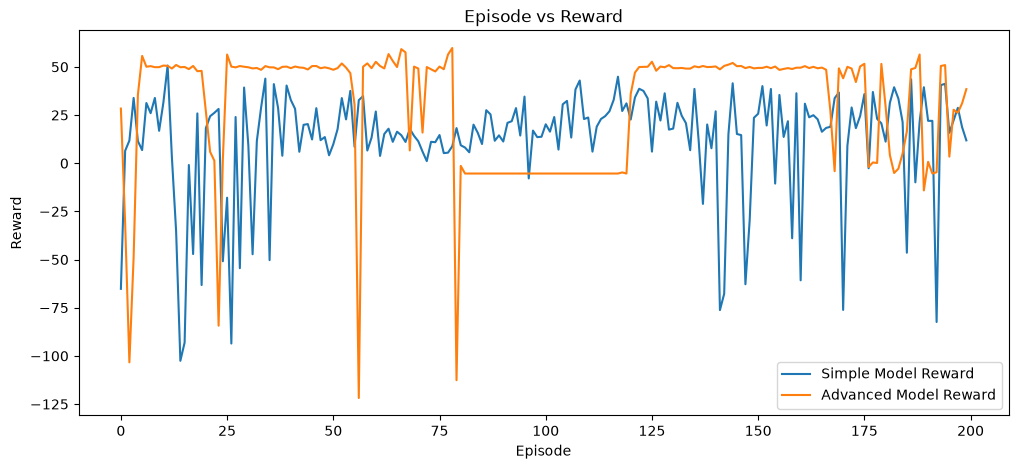

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.plot(simple_history_reward, label='Simple Model Reward')
plt.plot(advanced_history_reward, label='Advanced Model Reward')
plt.title('Episode vs Reward')
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.legend()


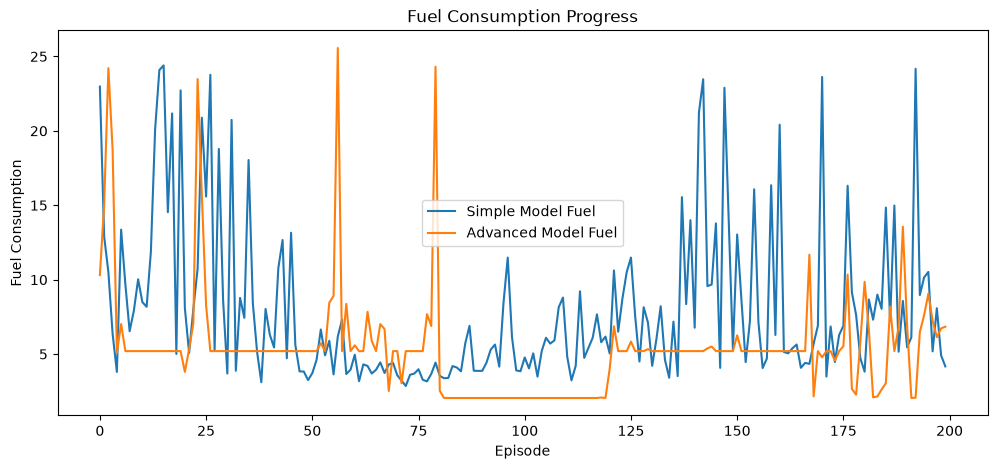

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(simple_history_fuel, label='Simple Model Fuel')
plt.plot(advanced_history_fuel, label='Advanced Model Fuel')
plt.title('Fuel Consumption Progress')
plt.xlabel('Episode')
plt.ylabel('Fuel Consumption')
plt.legend()

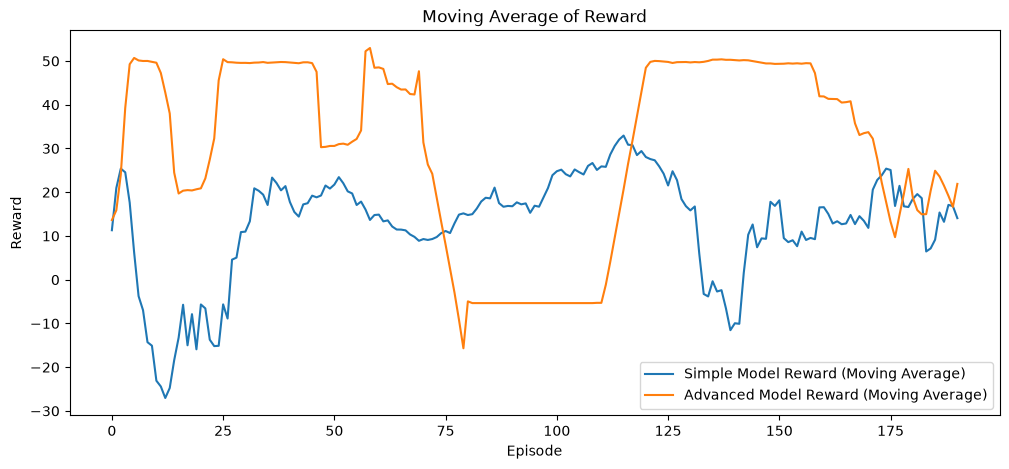

In [7]:
simple_moving_average_reward = np.convolve(simple_history_reward, np.ones(10)/10, mode='valid')
advanced_moving_average_reward = np.convolve(advanced_history_reward, np.ones(10)/10, mode='valid')

plt.figure(figsize=(12, 5))
plt.plot(simple_moving_average_reward, label='Simple Model Reward (Moving Average)')
plt.plot(advanced_moving_average_reward, label='Advanced Model Reward (Moving Average)')
plt.title('Moving Average of Reward')
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.legend()

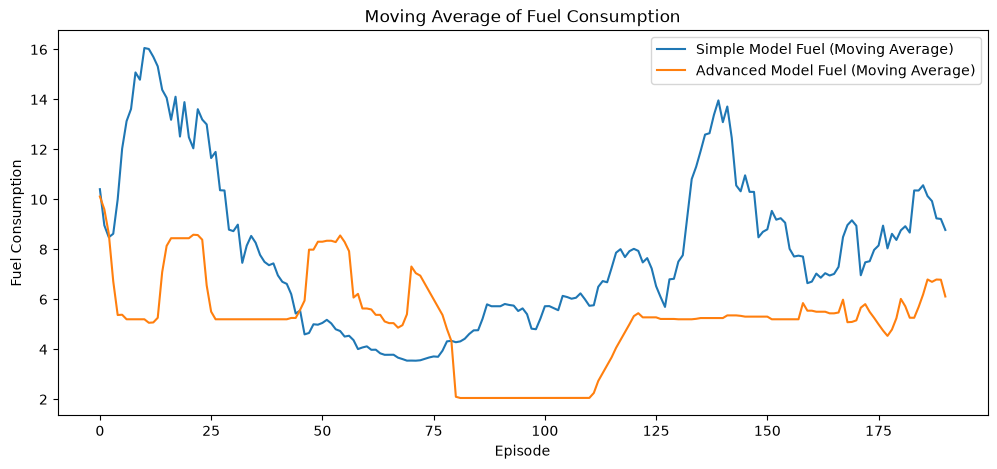

In [8]:
simple_moving_average_fuel = np.convolve(simple_history_fuel, np.ones(10)/10, mode='valid')
advanced_moving_average_fuel = np.convolve(advanced_history_fuel, np.ones(10)/10, mode='valid')

plt.figure(figsize=(12, 5))
plt.plot(simple_moving_average_fuel, label='Simple Model Fuel (Moving Average)')
plt.plot(advanced_moving_average_fuel, label='Advanced Model Fuel (Moving Average)')
plt.title('Moving Average of Fuel Consumption')
plt.xlabel('Episode')
plt.ylabel('Fuel Consumption')
plt.legend()

### Conclusion

The Simple Actor-Critic uses Monte Carlo learning, while the Advanced Actor-Critic uses one-step TD learning. Therefore, the Advanced method performed slightly better in this simulation.